# A self-driving lab on a computer: H2 PSA on activated carbon

A closed loop in the spirit of an autonomous flow-chemistry lab, with RUPTURA as the robot. `ruptura.selfdriving` holds
the technique: `PressureSwingCycle` builds a five-step PSA cycle with product backfill on the column of a base input,
runs it through the Python interface to its cyclic steady state, and turns the phase records into purity, recovery, and
productivity (the robot and its inline analytics); `Campaign` proposes batches of eight setups by batch Bayesian
optimization (the brain), runs them in parallel processes, and keeps the lab notebook, `campaign/experiments.csv`.

Here the feed is the 40/30/30 CO2/N2/H2 mixture of experiment T15 of Marx et al. on its activated carbon
(`examples/PSA-H2-activated-carbon`). The campaign maximizes the H2 productivity and recovery, both net of the H2 used
for purge and backfill, under H2 purity of at least 99.9 %, over eight variables: temperature, adsorption and purge
pressure, feed velocity, step time, purge-to-feed ratio, column length (at the sorbent mass of T15), and backfill share.
A second campaign optimizes the same cycle on two beds (`TwoBedPressureSwingCycle`): the beds are half a cycle apart,
valves between their product ends and a product tank carry the product and the purge, and a pressure equalization
takes the place of the backfill. The docstrings of `ruptura.selfdriving.psa` give the equations. The figures are sized for panels printed at half the
text width of the RUPTURA 2.0 paper.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ruptura.flowsheet import flowsheet_tikz
from ruptura.selfdriving import Campaign, PressureSwingCycle, TwoBedPressureSwingCycle, hypervolume, pareto_front

plt.rcParams.update({
    "figure.figsize": (8, 6),
    # The panels are printed at 0.49 of the A4 text width (3.07 in), i.e. at 38% of their 8 in width.
    # These sizes print as 8.1 pt (ticks, legends) and 8.8 pt (axis labels).
    "font.size": 23,
    "axes.labelsize": 23,
    "axes.titlesize": 25,
    "xtick.labelsize": 21,
    "ytick.labelsize": 21,
    "legend.fontsize": 21,
    "legend.title_fontsize": 21,
    "axes.labelpad": 6.0,
    "lines.linewidth": 3.0,
    "lines.markersize": 13,
    "lines.markeredgewidth": 1.8,
    "axes.linewidth": 1.5,
    "xtick.major.width": 1.5,
    "ytick.major.width": 1.5,
    "xtick.major.size": 7,
    "ytick.major.size": 7,
    "xtick.minor.width": 1.0,
    "ytick.minor.width": 1.0,
    "legend.handlelength": 1.2,
    "legend.labelspacing": 0.3,
    "legend.borderaxespad": 0.3,
    "legend.columnspacing": 1.0,
    "axes.grid": False,
    "savefig.dpi": 300,
    "pdf.fonttype": 42,
})
FIGURES = Path.cwd() / "figures"
FIGURES.mkdir(exist_ok=True)

## The campaign

`campaign.run()` runs the rounds that `campaign/experiments.csv` does not have yet: nothing for the finished campaign
of this folder, about 11 min on 8 cores from scratch (delete `campaign/` for that); the same for the two beds in
`campaign_two_beds/`. `campaign.write_inputs()` writes
the input of every experiment of the lab notebook again, and `campaign.rerun()` runs them all again, 8 at a time.

In [2]:
cycle = PressureSwingCycle(Path("../../..") / "examples" / "PSA-H2-activated-carbon" / "simulation.json", product="H2",
                           purity_target=0.999)
campaign = Campaign(cycle, Path("campaign"), rounds=15, batch_size=8, workers=8, seed=2026)
campaign.run()
two_beds = TwoBedPressureSwingCycle(Path("../../..") / "examples" / "PSA-H2-activated-carbon-two-beds" / "simulation.json", product="H2",
                                    purity_target=0.999)
two_bed_campaign = Campaign(two_beds, Path("campaign_two_beds"), rounds=15, batch_size=8, workers=8, seed=2026)
two_bed_campaign.run()
# The search space: bounds and scale of each variable (SI units), and the baseline cycle.
pd.DataFrame({name: [*bounds, cycle.baseline[name]] for name, bounds in cycle.variables.items()},
             index=["lower", "upper", "scale", "baseline"]).T

,lower,upper,scale,baseline
temperature,288.0,328.0,linear,298.0
high_pressure,400000.0,1000000.0,linear,1000000.0
low_pressure,100000.0,200000.0,linear,100000.0
feed_velocity,0.01,0.06,log,0.03
adsorption_time,20.0,200.0,log,30.0
purge_to_feed,0.02,0.6,log,0.266667
length,0.6,3.6,log,1.2
backfill,0.0,1.0,linear,0.0


In [3]:
def load_campaign(campaign, cycle):
    """The lab notebook of a campaign with the robot cycle, with the productivity in mmol/(kg s), the setup on the unit
    cube of the optimizer, and the feasible, Pareto-optimal, and baseline experiments marked."""
    data = pd.read_csv(campaign.log)
    data["productivity_mmol"] = 1.0e3 * data["productivity"]
    unit = cycle.to_unit(data.to_dict("records"))
    for k, name in enumerate(cycle.variables):
        data[f"unit_{name}"] = unit[:, k]
    data["feasible"] = (data["status"] != "failed") & (data["purity"] >= cycle.purity_target)
    feasible = data[data["feasible"]]
    data["pareto"] = False
    data.loc[feasible.index, "pareto"] = pareto_front(feasible[["productivity_mmol", "recovery"]].to_numpy())
    data["baseline"] = np.all([np.isclose(data[name], value) for name, value in cycle.baseline.items()], axis=0)
    return data


def hypervolume_history(data, reference=(0.0, 0.0)):
    """Hypervolume of the feasible experiments in (productivity in mmol/(kg s), recovery) after each experiment."""
    history = []
    for count in range(1, len(data) + 1):
        done = data.iloc[:count]
        points = done.loc[done["feasible"], ["productivity_mmol", "recovery"]].to_numpy()
        history.append(hypervolume(points, np.array(reference)))
    return np.array(history)


results = load_campaign(campaign, cycle)
pareto = results[results["pareto"]].sort_values("productivity_mmol")
baseline = results[results["baseline"]].iloc[0]
history = hypervolume_history(results)
print(f"{len(results)} experiments, {results['feasible'].sum()} at purity >= {cycle.purity_target}, "
      f"{len(pareto)} on the Pareto front, {(results['status'] != 'converged').sum()} not at the cyclic steady state")
print(f"baseline: productivity {baseline['productivity_mmol']:.3f} mmol/(kg s), recovery {baseline['recovery']:.3f}, "
      f"purity {baseline['purity']:.5f}")
for round_index in sorted(results["round"].unique()):
    done = results["round"] <= round_index
    batch = results[results["round"] == round_index]
    print(f"round {round_index:2d}: hypervolume {history[done.sum() - 1]:.3f}, "
          f"{batch['feasible'].sum()} of {len(batch)} at the target")
columns = ["index", "round", "productivity_mmol", "recovery", "purity", "backfill_to_feed", "cycle_time", "cycles",
           *cycle.variables]
pareto[columns].round(4)

136 experiments, 88 at purity >= 0.999, 5 on the Pareto front, 1 not at the cyclic steady state
baseline: productivity 0.584 mmol/(kg s), recovery 0.150, purity 0.99968
round  0: hypervolume 0.088, 10 of 16 at the target
round  1: hypervolume 0.091, 4 of 8 at the target
round  2: hypervolume 0.196, 8 of 8 at the target
round  3: hypervolume 0.243, 7 of 8 at the target
round  4: hypervolume 0.243, 5 of 8 at the target
round  5: hypervolume 0.311, 7 of 8 at the target
round  6: hypervolume 0.320, 5 of 8 at the target
round  7: hypervolume 0.382, 7 of 8 at the target
round  8: hypervolume 0.382, 1 of 8 at the target
round  9: hypervolume 0.382, 6 of 8 at the target
round 10: hypervolume 0.422, 6 of 8 at the target
round 11: hypervolume 0.436, 2 of 8 at the target
round 12: hypervolume 0.436, 5 of 8 at the target
round 13: hypervolume 0.439, 4 of 8 at the target
round 14: hypervolume 0.439, 6 of 8 at the target
round 15: hypervolume 0.440, 5 of 8 at the target


,index,round,productivity_mmol,recovery,purity,backfill_to_feed,cycle_time,cycles,temperature,high_pressure,low_pressure,feed_velocity,adsorption_time,purge_to_feed,length,backfill
100,100,11,0.4886,0.4459,0.9992,0.0000,692.6801,8,288.0,901040.5649,134099.3732,0.0600,117.5721,0.1574,3.6000,0.0000
90,90,10,0.9633,0.4160,0.9993,0.0433,357.5098,11,288.0,1000000.0000,131367.6670,0.0293,126.4232,0.1629,1.6013,0.0875
133,133,15,1.0002,0.3805,0.9996,0.0468,285.5191,12,288.0,993891.3501,134615.9800,0.0264,104.6672,0.1591,1.3905,0.0853
112,112,13,1.0180,0.3555,0.9993,0.0176,240.9382,13,288.0,908128.7826,129704.9874,0.0341,80.4992,0.1913,1.4690,0.0348
48,48,5,1.0316,0.3015,0.9992,0.0040,175.6473,14,288.0,803148.7616,103039.8602,0.0329,59.8133,0.2178,1.1557,0.0090


## Convergence of the campaign

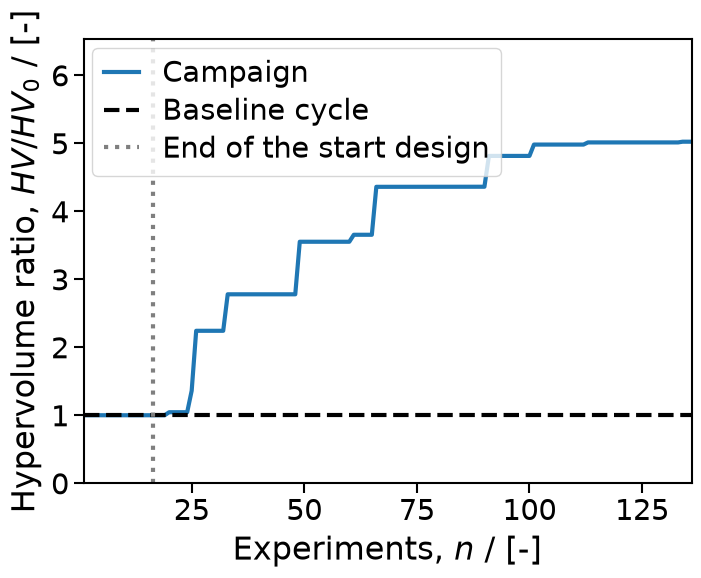

In [4]:
data = load_campaign(campaign, cycle)
history = hypervolume_history(data)
baseline_index = int(data.index[data["baseline"]][0])
baseline_value = hypervolume(data.loc[[baseline_index], ["productivity_mmol", "recovery"]].to_numpy(), np.zeros(2))
first_round = int((data["round"] == 0).sum())

# Relative to the hypervolume of the baseline cycle alone, the rectangle of its productivity and recovery.
ratio = history / baseline_value

fig, ax = plt.subplots()
ax.plot(np.arange(1, len(history) + 1), ratio, color="C0", label="Campaign")
ax.axhline(1.0, color="k", linestyle="--", label="Baseline cycle")
ax.axvline(first_round + 0.5, color="C7", linestyle=":", label="End of the start design")
ax.set_xlabel("Experiments, $n$ / [-]")
ax.set_ylabel("Hypervolume ratio, $HV/HV_0$ / [-]")
ax.set_xlim(1, len(history))
ax.set_ylim(0.0, 1.3 * ratio.max())
ax.legend(loc="upper left")
# The same plot box as the impurity figure, below it in the paper, whose tick labels are wider.
fig.subplots_adjust(left=0.20, right=0.96, bottom=0.20, top=0.94)
fig.savefig(FIGURES / "hypervolume.pdf", dpi=300)
plt.show()

## Productivity against recovery

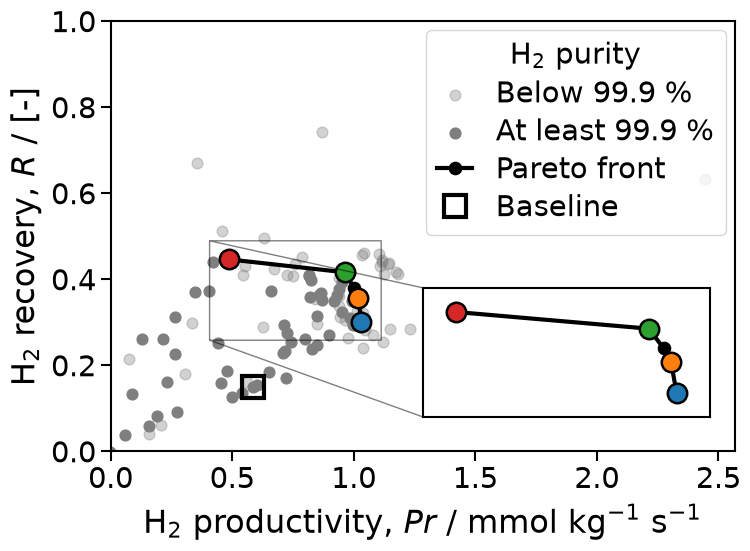

In [5]:
data = load_campaign(campaign, cycle)
feasible = data[data["feasible"]]
infeasible = data[~data["feasible"] & (data["status"] != "failed")]
front = data[data["pareto"]].sort_values("productivity_mmol")
start = data[data["baseline"]]
target = f"{100 * cycle.purity_target:g} %"
# The setups of the Pareto-front figure, in its colors: up to four, from the most productive one.
ordered = front.sort_values("productivity_mmol", ascending=False)
shown = ordered.iloc[np.unique(np.linspace(0, len(ordered) - 1, min(len(ordered), 4)).round().astype(int))]

fig, ax = plt.subplots()
ax.scatter(infeasible["productivity_mmol"], infeasible["recovery"], s=60, color="C7", alpha=0.35,
           label=f"Below {target}")
ax.scatter(feasible["productivity_mmol"], feasible["recovery"], s=60, color="C7", label=f"At least {target}")
ax.plot(front["productivity_mmol"], front["recovery"], color="k", marker="o", markersize=8, label="Pareto front")
# The front is short: a zoom without ticks (the values are in the legend of the Pareto-front figure) shows its setups.
inset = ax.inset_axes([0.50, 0.08, 0.46, 0.30])
inset.plot(front["productivity_mmol"], front["recovery"], color="k", marker="o", markersize=8)
for k, (_, design) in enumerate(shown.iterrows()):
    for axis in (ax, inset):
        axis.plot(design["productivity_mmol"], design["recovery"], linestyle="none", marker="o", markersize=14,
                  color=f"C{k}", markeredgecolor="k", zorder=3)
x_margin = 0.15 * np.ptp(front["productivity_mmol"])
y_margin = 0.3 * np.ptp(front["recovery"])
inset.set_xlim(front["productivity_mmol"].min() - x_margin, front["productivity_mmol"].max() + x_margin)
inset.set_ylim(front["recovery"].min() - y_margin, front["recovery"].max() + y_margin)
inset.set_xticks([])
inset.set_yticks([])
ax.indicate_inset_zoom(inset, edgecolor="k")
ax.plot(start["productivity_mmol"], start["recovery"], linestyle="none", marker="s", markersize=16,
        markerfacecolor="none", markeredgecolor="k", markeredgewidth=3, label="Baseline")
ax.set_xlabel("H$_2$ productivity, $Pr$ / mmol kg$^{-1}$ s$^{-1}$")
ax.set_ylabel("H$_2$ recovery, $R$ / [-]")
ax.set_xlim(0.0, 1.05 * data["productivity_mmol"].max())
ax.set_ylim(0.0, 1.0)
ax.legend(loc="upper right", title="H$_2$ purity")
fig.tight_layout()
fig.savefig(FIGURES / "pareto_front.pdf", dpi=300)
plt.show()

## Purity of every experiment

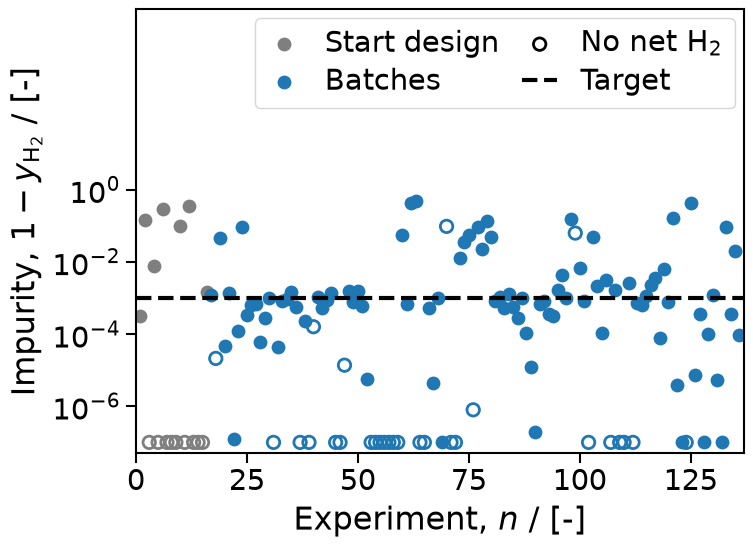

In [6]:
data = load_campaign(campaign, cycle)
done = data[data["status"] != "failed"]
start = done[done["round"] == 0]
batches = done[done["round"] > 0]
# Below 1e-7 the impurity is integration noise (no N2 leaves the column); such runs are drawn at 1e-7.
floor = 1.0e-7
ticks = [1.0e-6, 1.0e-4, 1.0e-2, 1.0]

fig, ax = plt.subplots()
# A cycle whose purge and backfill take more H2 than it produces (recovery <= 0) flushes the column with H2: its product
# is pure, but there is no net product. Such runs are drawn open.
for group, color, label in ((start, "C7", "Start design"), (batches, "C0", "Batches")):
    net = group["recovery"] > 0.0
    ax.scatter(group.loc[net, "index"] + 1, np.maximum(1.0 - group.loc[net, "purity"], floor), s=80, color=color,
               label=label)
    ax.scatter(group.loc[~net, "index"] + 1, np.maximum(1.0 - group.loc[~net, "purity"], floor), s=80,
               facecolors="none", edgecolors=color, linewidths=2)
ax.scatter([], [], s=80, facecolors="none", edgecolors="k", linewidths=2, label="No net H$_2$")
ax.axhline(1.0 - cycle.purity_target, color="k", linestyle="--", label="Target")
ax.set_yscale("log")
ax.set_yticks(ticks, [r"$10^{-6}$", r"$10^{-4}$", r"$10^{-2}$", r"$10^{0}$"])
ax.set_yticks([], minor=True)
ax.set_ylim(0.5 * floor, 1.0e5)
ax.set_xlabel("Experiment, $n$ / [-]")
ax.set_ylabel(r"Impurity, $1 - y_{\mathrm{H_2}}$ / [-]")
ax.set_xlim(0, len(data) + 1)
ax.legend(loc="upper right", ncol=2, columnspacing=0.8)
# The same plot box as the hypervolume figure, above it in the paper.
fig.subplots_adjust(left=0.20, right=0.96, bottom=0.20, top=0.94)
fig.savefig(FIGURES / "impurity.pdf", dpi=300)
plt.show()

## What the Pareto-optimal cycles look like

Setups along the Pareto front, from the most productive to the one with the highest recovery, on the unit cube of the
optimizer: 0 and 1 are the bounds of each variable, on a log scale for the feed velocity $v_F$, the adsorption time
$t_{\mathrm{ads}}$, the purge-to-feed ratio $G$, and the length $L$; $b$ is the share of the pressurization made with
product H2 (backfill).

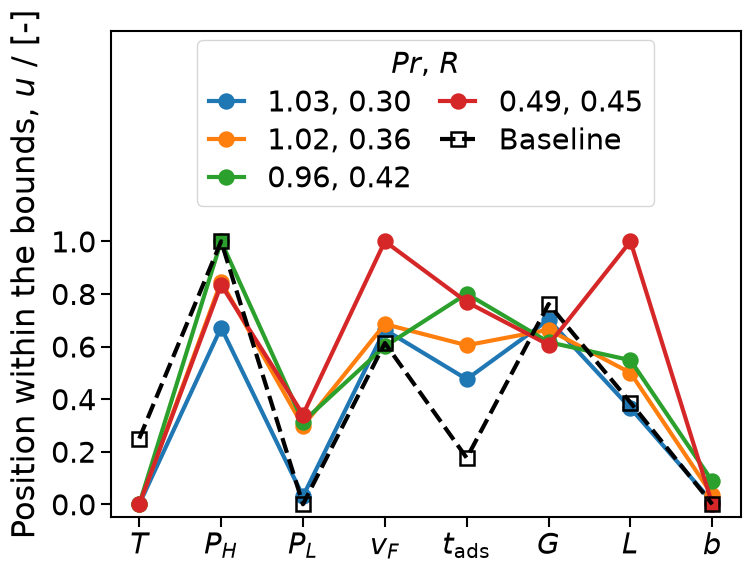

In [7]:
data = load_campaign(campaign, cycle)
front = data[data["pareto"]].sort_values("productivity_mmol", ascending=False)
shown = front.iloc[np.unique(np.linspace(0, len(front) - 1, min(len(front), 4)).round().astype(int))]
start = data[data["baseline"]].iloc[0]
labels = ["$T$", "$P_H$", "$P_L$", "$v_F$", r"$t_{\mathrm{ads}}$", "$G$", "$L$", "$b$"]
positions = np.arange(len(cycle.variables))

fig, ax = plt.subplots()
for k, (_, design) in enumerate(shown.iterrows()):
    ax.plot(positions, [design[f"unit_{name}"] for name in cycle.variables], color=f"C{k}", marker="o", markersize=10,
            label=f"{design['productivity_mmol']:.2f}, {design['recovery']:.2f}")
ax.plot(positions, [start[f"unit_{name}"] for name in cycle.variables], color="k", linestyle="--", marker="s",
        markersize=10, markerfacecolor="none", label="Baseline")
ax.set_xticks(positions, labels)
ax.set_ylabel("Position within the bounds, $u$ / [-]")
# Room above the bounds for the legend, which would otherwise hide some of the setups.
ax.set_ylim(-0.05, 1.8)
ax.set_yticks(np.linspace(0.0, 1.0, 6))
# Productivity in mmol/(kg s) and recovery of each setup.
ax.legend(title="$Pr$, $R$", loc="upper center", ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "pareto_setups.pdf", dpi=300)
plt.show()

## Two beds with pressure equalization

The same feed, sorbent, constraint, and search on two beds (`TwoBedPressureSwingCycle`), with `BoundaryCondition`
`MomentumBalance`: the variables of the one-column campaign with the pressure equalization $e$, the share of
$P_H - P_L$ by which the bed that was purged rises before its feed pressurization, in place of the backfill $b$. The
product is what reaches the tank, and the productivity is per kg of the sorbent of both beds.

In [8]:
results = load_campaign(two_bed_campaign, two_beds)
pareto = results[results["pareto"]].sort_values("productivity_mmol")
baseline = results[results["baseline"]].iloc[0]
history = hypervolume_history(results)
print(f"{len(results)} experiments, {results['feasible'].sum()} at purity >= {two_beds.purity_target}, "
      f"{len(pareto)} on the Pareto front, {(results['status'] != 'converged').sum()} not at the cyclic steady state")
print(f"baseline: productivity {baseline['productivity_mmol']:.3f} mmol/(kg s), recovery {baseline['recovery']:.3f}, "
      f"purity {baseline['purity']:.5f}")
for round_index in sorted(results["round"].unique()):
    done = results["round"] <= round_index
    batch = results[results["round"] == round_index]
    print(f"round {round_index:2d}: hypervolume {history[done.sum() - 1]:.3f}, "
          f"{batch['feasible'].sum()} of {len(batch)} at the target")
columns = ["index", "round", "productivity_mmol", "recovery", "purity", "cycle_time", "cycles", *two_beds.variables]
pareto[columns].round(4)

136 experiments, 69 at purity >= 0.999, 4 on the Pareto front, 10 not at the cyclic steady state
baseline: productivity 0.562 mmol/(kg s), recovery 0.144, purity 0.99956
round  0: hypervolume 0.169, 2 of 16 at the target
round  1: hypervolume 0.188, 7 of 8 at the target
round  2: hypervolume 0.191, 7 of 8 at the target
round  3: hypervolume 0.191, 3 of 8 at the target
round  4: hypervolume 0.301, 6 of 8 at the target
round  5: hypervolume 0.320, 5 of 8 at the target
round  6: hypervolume 0.363, 6 of 8 at the target
round  7: hypervolume 0.386, 3 of 8 at the target
round  8: hypervolume 0.480, 4 of 8 at the target
round  9: hypervolume 0.495, 1 of 8 at the target
round 10: hypervolume 0.533, 3 of 8 at the target
round 11: hypervolume 0.535, 4 of 8 at the target
round 12: hypervolume 0.618, 3 of 8 at the target
round 13: hypervolume 0.637, 5 of 8 at the target
round 14: hypervolume 0.668, 4 of 8 at the target
round 15: hypervolume 0.708, 6 of 8 at the target


,index,round,productivity_mmol,recovery,purity,cycle_time,cycles,temperature,high_pressure,low_pressure,feed_velocity,adsorption_time,purge_to_feed,length,equalization
131,131,15,0.2064,0.5921,1.0000,943.2932,9,295.3121,659599.6,100000.0,0.0600,76.6208,0.0995,3.3817,0.5000
121,121,14,1.0373,0.5558,0.9991,256.1731,14,288.0000,1000000.0,100000.0,0.0384,41.1002,0.1336,1.2513,0.5000
119,119,13,1.0696,0.5199,0.9992,230.7746,15,288.0000,1000000.0,100000.0,0.0356,40.8767,0.1550,1.1581,0.5000
133,133,15,1.2784,0.5128,0.9992,196.4069,15,288.0000,1000000.0,100000.0,0.0373,40.9260,0.1649,1.1696,0.4316


### The two-bed system

`ruptura.flowsheet` draws the columns, the tank, and the valves of the input as TikZ, here with the connections of the
adsorption of bed A in black and the ports of that phase. `figures/two_bed_flowsheet.tex` goes into a figure with
`\input`; it needs only `\usepackage{tikz}`.

In [9]:
system = two_beds.simulation_input({**two_beds.baseline, "equalization": 0.25})
(FIGURES / "two_bed_flowsheet.tex").write_text(flowsheet_tikz(system, "Adsorption A, purge B"), encoding="utf-8")

1788

### Productivity against recovery on one column and on two beds

The experiments at the target and the Pareto front of each campaign, with its baseline cycle (open square).

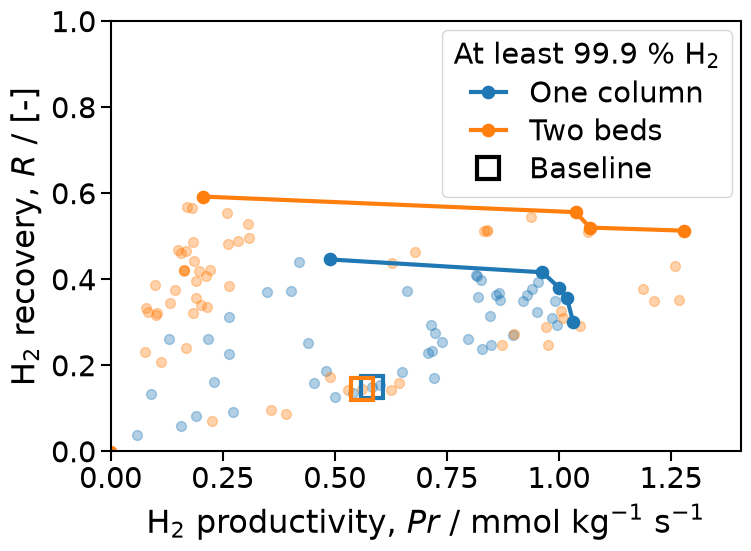

In [10]:
fig, ax = plt.subplots()
largest = 0.0
for k, (lab, robot, label) in enumerate(((campaign, cycle, "One column"), (two_bed_campaign, two_beds, "Two beds"))):
    data = load_campaign(lab, robot)
    feasible = data[data["feasible"]]
    front = data[data["pareto"]].sort_values("productivity_mmol")
    start = data[data["baseline"]]
    largest = max(largest, feasible["productivity_mmol"].max())
    ax.scatter(feasible["productivity_mmol"], feasible["recovery"], s=50, color=f"C{k}", alpha=0.35)
    ax.plot(front["productivity_mmol"], front["recovery"], color=f"C{k}", marker="o", markersize=8, label=label)
    ax.plot(start["productivity_mmol"], start["recovery"], linestyle="none", marker="s", markersize=16,
            markerfacecolor="none", markeredgecolor=f"C{k}", markeredgewidth=3)
ax.plot([], [], linestyle="none", marker="s", markersize=16, markerfacecolor="none", markeredgecolor="k",
        markeredgewidth=3, label="Baseline")
ax.set_xlabel("H$_2$ productivity, $Pr$ / mmol kg$^{-1}$ s$^{-1}$")
ax.set_ylabel("H$_2$ recovery, $R$ / [-]")
ax.set_xlim(0.0, 1.1 * largest)
ax.set_ylim(0.0, 1.0)
ax.legend(loc="upper right", title=f"At least {100 * cycle.purity_target:g} % H$_2$")
fig.tight_layout()
fig.savefig(FIGURES / "pareto_front_two_beds.pdf", dpi=300)
plt.show()

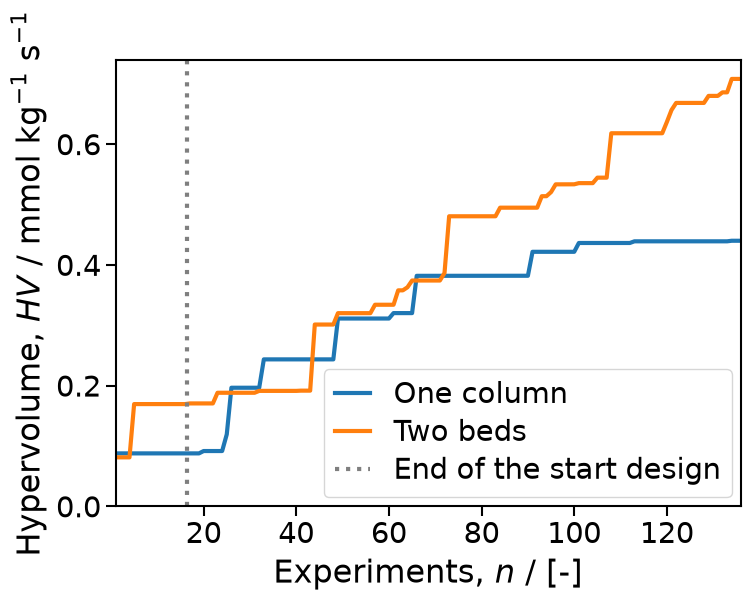

In [11]:
fig, ax = plt.subplots()
for k, (lab, robot, label) in enumerate(((campaign, cycle, "One column"), (two_bed_campaign, two_beds, "Two beds"))):
    data = load_campaign(lab, robot)
    history = hypervolume_history(data)
    ax.plot(np.arange(1, len(history) + 1), history, color=f"C{k}", label=label)
ax.axvline(int((data["round"] == 0).sum()) + 0.5, color="C7", linestyle=":", label="End of the start design")
ax.set_xlabel("Experiments, $n$ / [-]")
# The area between (0, 0) and the feasible experiments in productivity and recovery.
ax.set_ylabel("Hypervolume, $HV$ / mmol kg$^{-1}$ s$^{-1}$")
ax.set_xlim(1, len(history))
ax.set_ylim(0.0, None)
ax.legend(loc="lower right")
fig.tight_layout()
fig.savefig(FIGURES / "hypervolume_two_beds.pdf", dpi=300)
plt.show()

### What the Pareto-optimal two-bed cycles look like

As for one column, with the pressure equalization $e$ in place of the backfill $b$.

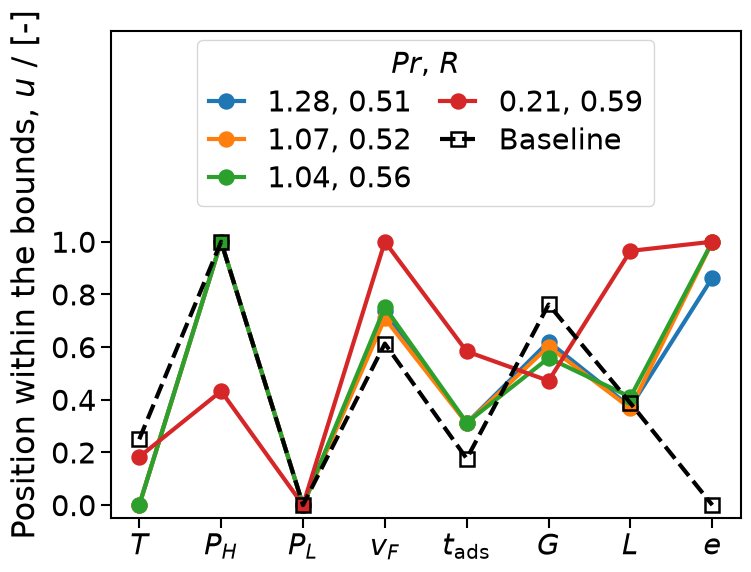

In [12]:
data = load_campaign(two_bed_campaign, two_beds)
front = data[data["pareto"]].sort_values("productivity_mmol", ascending=False)
shown = front.iloc[np.unique(np.linspace(0, len(front) - 1, min(len(front), 4)).round().astype(int))]
start = data[data["baseline"]].iloc[0]
labels = ["$T$", "$P_H$", "$P_L$", "$v_F$", r"$t_{\mathrm{ads}}$", "$G$", "$L$", "$e$"]
positions = np.arange(len(two_beds.variables))

fig, ax = plt.subplots()
for k, (_, design) in enumerate(shown.iterrows()):
    ax.plot(positions, [design[f"unit_{name}"] for name in two_beds.variables], color=f"C{k}", marker="o",
            markersize=10, label=f"{design['productivity_mmol']:.2f}, {design['recovery']:.2f}")
ax.plot(positions, [start[f"unit_{name}"] for name in two_beds.variables], color="k", linestyle="--", marker="s",
        markersize=10, markerfacecolor="none", label="Baseline")
ax.set_xticks(positions, labels)
ax.set_ylabel("Position within the bounds, $u$ / [-]")
# Room above the bounds for the legend, which would otherwise hide some of the setups.
ax.set_ylim(-0.05, 1.8)
ax.set_yticks(np.linspace(0.0, 1.0, 6))
# Productivity in mmol/(kg s) and recovery of each setup.
ax.legend(title="$Pr$, $R$", loc="upper center", ncol=2)
fig.tight_layout()
fig.savefig(FIGURES / "pareto_setups_two_beds.pdf", dpi=300)
plt.show()

## Paper figure: both campaigns in one row

The Pareto fronts, the hypervolume, and the impurity of the one-column experiments; the separate panels above are SI panels.

In [ ]:
# Paper figure: both campaigns in one row.  One figure for the full text width (6.27 in), as the work-precision row of
# the integrator benchmark, so the 21-23 pt fonts print at about 8 pt.
labs = ((campaign, cycle, "C0", "o", "One column"), (two_bed_campaign, two_beds, "C1", "s", "Two beds"))
fig, (ax, middle, right) = plt.subplots(1, 3, figsize=(16.0, 5.6))

# (a) Recovery against productivity: every experiment in grey (light: below the purity target), the Pareto fronts of the
# experiments at the target in black, and the baselines as open squares.
for lab, robot, color, marker, label in labs:
    data = load_campaign(lab, robot)
    feasible = data[data["feasible"]]
    infeasible = data[~data["feasible"] & (data["status"] != "failed")]
    front = data[data["pareto"]].sort_values("productivity_mmol")
    start = data[data["baseline"]]
    ax.scatter(infeasible["productivity_mmol"], infeasible["recovery"], s=45, color="C7", alpha=0.3, marker=marker)
    ax.scatter(feasible["productivity_mmol"], feasible["recovery"], s=45, color="C7", marker=marker)
    ax.plot(front["productivity_mmol"], front["recovery"], color="k", marker=marker, markersize=12, markerfacecolor=color,
            markeredgecolor="k", label=label)
    ax.plot(start["productivity_mmol"], start["recovery"], linestyle="none", marker="s", markersize=17,
            markerfacecolor="none", markeredgecolor=color, markeredgewidth=3)
ax.plot([], [], linestyle="none", marker="s", markersize=17, markerfacecolor="none", markeredgecolor="k", markeredgewidth=3,
        label="Baseline")
ax.set_xlabel("Productivity, $Pr$ / mmol kg$^{-1}$ s$^{-1}$")
ax.set_ylabel("H$_2$ recovery, $R$ / [-]")
ax.set_xlim(0.0, None)
ax.set_ylim(0.0, 1.0)
ax.legend(loc="upper right")

# (b) Hypervolume of the experiments at the target, relative to that of the baseline cycle of each campaign.
for lab, robot, color, marker, label in labs:
    data = load_campaign(lab, robot)
    history = hypervolume_history(data)
    baseline_index = int(data.index[data["baseline"]][0])
    baseline_value = hypervolume(data.loc[[baseline_index], ["productivity_mmol", "recovery"]].to_numpy(), np.zeros(2))
    middle.plot(np.arange(1, len(history) + 1), history / baseline_value, color=color, label=label)
middle.axhline(1.0, color="k", linestyle="--")
middle.axvline(int((data["round"] == 0).sum()) + 0.5, color="C7", linestyle=":")
middle.set_xlabel("Experiments, $n$ / [-]")
middle.set_ylabel("Hypervolume, $HV/HV_0$ / [-]")
middle.set_xlim(1, len(history))
middle.set_ylim(0.0, None)
middle.legend(loc="upper left")

# (c) Product impurity of every one-column experiment; open symbols: no net H2 product (recovery <= 0).  Below 1e-7 the
# impurity is integration noise (no N2 leaves the column); such runs are drawn at 1e-7.
data = load_campaign(campaign, cycle)
done = data[data["status"] != "failed"]
floor = 1.0e-7
for group, color, label in ((done[done["round"] == 0], "C7", "Start"), (done[done["round"] > 0], "C0", "Batches")):
    net = group["recovery"] > 0.0
    right.scatter(group.loc[net, "index"] + 1, np.maximum(1.0 - group.loc[net, "purity"], floor), s=70, color=color,
                  label=label)
    right.scatter(group.loc[~net, "index"] + 1, np.maximum(1.0 - group.loc[~net, "purity"], floor), s=70,
                  facecolors="none", edgecolors=color, linewidths=2)
right.axhline(1.0 - cycle.purity_target, color="k", linestyle="--", label="Target")
right.set_yscale("log")
right.set_yticks([1.0e-6, 1.0e-4, 1.0e-2, 1.0], [r"$10^{-6}$", r"$10^{-4}$", r"$10^{-2}$", r"$10^{0}$"])
right.set_yticks([], minor=True)
right.set_ylim(0.5 * floor, 1.0e4)
right.set_xlim(0, len(data) + 1)
right.set_xlabel("Experiment, $n$ / [-]")
right.set_ylabel(r"Impurity, $1 - y_{\mathrm{H_2}}$ / [-]")
right.legend(loc="upper right", ncol=3, columnspacing=0.6, handletextpad=0.2)

for axis, letter in ((ax, "(a)"), (middle, "(b)"), (right, "(c)")):
    axis.text(0.5, -0.27, letter, transform=axis.transAxes, ha="center", va="top")
fig.tight_layout()
fig.savefig(FIGURES / "campaigns.pdf", dpi=300, bbox_inches="tight")
plt.show()
